# Importing Libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import roc_curve, auc
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings('ignore')

# Reading Data

In [4]:
df=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\1053\\Data\\Code Dataset\\EDA_Dataset.csv")

In [5]:
df.columns

Index(['Unnamed: 0', 'SUBJID', 'AGE', 'SEXCD', 'TRTDOSE', 'TRTFREQ', 'TRT',
       'ACHEMO', 'ACHEMMCD', 'FCHEMOCD', 'B_LESNM', 'B_LESNMT', 'B_LESNMN',
       'B_METANM', 'PFSCR', 'INFREAC', 'BAWDOSE', 'OXCWDOSE', 'OXAWDOSE',
       'IRCDOSE', 'IRCWDOSE', 'FBCDOSE', 'FBCWDOSE', 'FICDOSE', 'FICWDOSE',
       'DUREXP', 'IRDSINTR', 'FBDURWK', 'FBDSINT', 'TRTDUR', 'CHANY5YR_N',
       'CHANY5YR_Y', 'CHREGPT_FLUOROURACIL', 'CHREGPT_FOLINIC ACID',
       'CHREGCLS_DETOXIFYING AGENTS FOR ANTINEOPLASTIC TREATMENT',
       'CHREGCLS_PYRIMIDINE ANALOGUES', 'DTHDY', 'DTCAUS', 'BIOPSITP',
       'BIOPTISB', 'BIOPTISS', 'BIOPSITP.1', 'BIOPSITM', 'ICSIGN', 'LDOSDSDY',
       'EOIP', 'EOTA', 'DSDOSDY', 'DSEOSYN', 'DSEOS', 'EOIPDY', 'EOBDY',
       'EOXIRDY', 'EOLEUDY', 'QTY', 'DOSE', 'ACTTRT_5-Fluorouracil',
       'ACTTRT_5-Fluorouracil 22 hour', 'ACTTRT_5-Fluorouracil 46 hour',
       'ACTTRT_5-Fluorouracil bolus', 'ACTTRT_Bevacizumab',
       'ACTTRT_Irinotecan', 'ACTTRT_Leucovorin', 'ACTTRT_Oxali

In [6]:
df.shape

(4765, 89)

In [7]:
df.head()

,Unnamed: 0,SUBJID,AGE,SEXCD,TRTDOSE,TRTFREQ,TRT,ACHEMO,ACHEMMCD,FCHEMOCD,...,SXANY5YR_N,SXANY5YR_Y,SXTYPE_Biopsy,SXTYPE_Laparoscopic,SXTYPE_Open,SXTYPE_Other,SXTYPE_Resection,SXTYPE_Surgery,VSSTRES,VSBLRES
0,0,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
1,1,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
2,2,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
3,3,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428
4,4,249101001,67.0,F,6.0,Every 2 weeks,panit. plus bevacizumab with chemotherapy,Oxaliplatin,78.0,78.0,...,0,1,0,0,0,0,1,1,64.648471,67.814428


In [8]:
df['LSNEWANY'].unique()

array(['N', 'Y'], dtype=object)

# Feature Selection by Random Forest

In [10]:
df1=df

In [11]:
df1['LSNEWANY'] = df1['LSNEWANY'].astype('category').cat.codes

In [12]:
df1 = pd.get_dummies(df1, drop_first=True)

In [13]:
# Separate features and target
X = df1.drop('LSNEWANY', axis=1)
y = df1['LSNEWANY']

In [14]:
# Separate features and target
X = df1.drop('LSNEWANY', axis=1)
y = df1['LSNEWANY']

In [21]:
# Train a Random Forest model
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

RandomForestClassifier(random_state=42)

In [27]:
importances = rf.feature_importances_

In [28]:
# Create a dataframe for feature importances
feature_importances_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

In [29]:
feature_importances_df.head(40)

,Feature,Importance
53,DOSREFDY,0.268608
54,LSSLD,0.162101
0,Unnamed: 0,0.076860
55,LSSLD_Diff,0.030304
56,Percentage_LSSLD_Change,0.027899
10,PFSCR,0.027517
100,LSCAT_x_Target lesion,0.022843
99,LSCAT_x_Non-target lesion,0.020179
31,DTHDY,0.018818
33,DSDOSDY,0.013697


# Forming New Datasets

In [31]:
df=df[['SUBJID','LSNEWANY','LSSLD','PFSCR','TRTDUR','OXAWDOSE','EOBDY','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','EOXIRDY','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
df.shape

(4765, 27)

In [32]:
df.head()

,SUBJID,LSNEWANY,LSSLD,PFSCR,TRTDUR,OXAWDOSE,EOBDY,OXCWDOSE,LBORRESN,LDOSDSDY,...,FBCDOSE,VSBLRES,FICWDOSE,DOSE,EOXIRDY,B_LESNM,B_LESNMN,B_LESNMT,IRCDOSE,IRDSINTR
0,249101001,0,NaN,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
1,249101001,0,NaN,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
2,249101001,1,22.000000,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
3,249101001,1,22.000000,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN
4,249101001,0,25.444444,1.0,685.0,82.320685,685.0,1564.093013,37.302478,685.0,...,27360.0,67.814428,21930.575071,635.377778,281.0,100.0,99.0,1.0,NaN,NaN


In [35]:
dfnew=df.drop_duplicates(keep='first')
dfnew.shape

(1570, 27)

In [41]:
result1=dfnew

# Logistic Regression

In [44]:
result1.shape

(1570, 27)

In [46]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes

In [48]:
result1.fillna(0, inplace=True)

In [50]:
X=result1[['LSSLD','PFSCR','TRTDUR','OXAWDOSE','EOBDY','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','EOXIRDY','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
y=result1[['LSNEWANY']]

In [52]:
result1['LSNEWANY'] = result1['LSNEWANY'].astype('category').cat.codes

In [54]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [56]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [58]:
model11= LogisticRegression()

In [60]:
model11.fit(X_train_scaled, y_train)

LogisticRegression()

In [62]:
y_pred = model11.predict(X_test_scaled)

In [64]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.8280


In [66]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[260   0]
 [ 54   0]]


In [68]:
class_report = classification_report(y_test, y_pred)
print("Classification Report:")
print(class_report)

Classification Report:
              precision    recall  f1-score   support

           0       0.83      1.00      0.91       260
           1       0.00      0.00      0.00        54

    accuracy                           0.83       314
   macro avg       0.41      0.50      0.45       314
weighted avg       0.69      0.83      0.75       314



In [70]:
y_train_pred = model11.predict(X_train_scaled)

y_test_pred = model11.predict(X_test_scaled)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training Accuracy: {train_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

Training Accuracy: 0.8280
Test Accuracy: 0.8280


# XGBoost Regression

!pip install xgboost

In [34]:
import xgboost as xgb

In [35]:
features=result1[['LSSLD','PFSCR','TRTDUR','OXAWDOSE','EOBDY','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','EOXIRDY','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
target=result1[['LSNEWANY']]

In [36]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, target, test_size=0.2, random_state=42)

In [38]:
# Initialize and fit the XGBoost model
model12 = xgb.XGBClassifier(use_label_encoder=False, eval_metric='logloss')
model12.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [39]:
y_pred = model12.predict(X_test)

In [40]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print("Confusion Matrix:")
print(conf_matrix)
print("Classification Report:")
print(class_report)

Accuracy: 0.7389
Confusion Matrix:
[[226  34]
 [ 48   6]]
Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.87      0.85       260
           1       0.15      0.11      0.13        54

    accuracy                           0.74       314
   macro avg       0.49      0.49      0.49       314
weighted avg       0.71      0.74      0.72       314



# Regression with Linear,Decision Tree,Random Forest,Gadient Boosting,Support Vector and Neural Network

In [41]:
features=result1[['LSSLD','PFSCR','TRTDUR','OXAWDOSE','EOBDY','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','EOXIRDY','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
target=result1[['LSNEWANY']]

In [42]:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=42)

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(),
    "Random Forest": RandomForestRegressor(),
    "Gradient Boosting": GradientBoostingRegressor(),
    "Support Vector Regression": make_pipeline(StandardScaler(), SVR()),
    "Neural Network": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(100, 50), max_iter=1000))
}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Calculate Mean Squared Error and R² Score
    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    print(f"{name} - Mean Squared Error: {mse}, R² Score: {r2}")


Linear Regression - Mean Squared Error: 0.13490519027694287, R² Score: 0.052627340416990354
Decision Tree - Mean Squared Error: 0.2961783439490446, R² Score: -1.0799145299145296
Random Forest - Mean Squared Error: 0.17285019042022332, R² Score: -0.2138416933527303
Gradient Boosting - Mean Squared Error: 0.14919332304035296, R² Score: -0.047711173681384444
Support Vector Regression - Mean Squared Error: 0.15031034276234953, R² Score: -0.0555554526350861
Neural Network - Mean Squared Error: 0.19056986473415688, R² Score: -0.3382782324308353


# ROC and AUC

In [43]:
X, y = make_classification(n_samples=1000, n_features=20, 
                           n_informative=2, n_redundant=10, 
                           random_state=42)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [44]:
# Train a model
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict probabilities
y_score = model.predict_proba(X_test)[:, 1]

# Compute ROC curve and ROC AUC
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

In [45]:
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 0.84


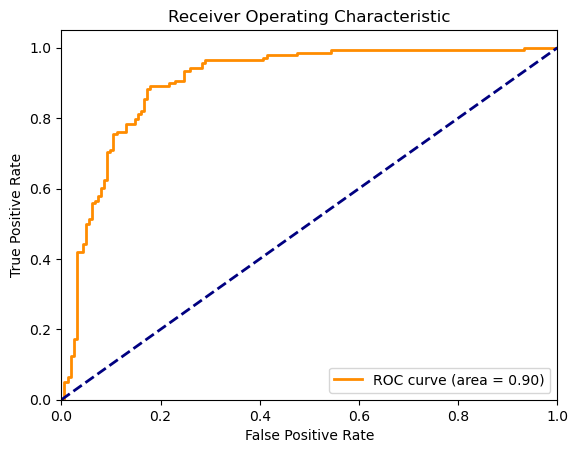

In [46]:
# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic')
plt.legend(loc="lower right")
plt.show()

# KNN Classifier:

In [47]:
X=result1[['LSSLD','PFSCR','TRTDUR','OXAWDOSE','EOBDY','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','EOXIRDY','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR']]
y=result1[['LSNEWANY']]

In [48]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Initialize the KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)

In [49]:
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [50]:
y_pred = knn.predict(X_test)

In [51]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred)

print(f'Accuracy: {accuracy}')
print('Confusion Matrix:')
print(conf_matrix)
print('Classification Report:')
print(class_report)

Accuracy: 0.8633333333333333
Confusion Matrix:
[[142  20]
 [ 21 117]]
Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.88      0.87       162
           1       0.85      0.85      0.85       138

    accuracy                           0.86       300
   macro avg       0.86      0.86      0.86       300
weighted avg       0.86      0.86      0.86       300



# Conclusion:

# Feature Selections for Regression:

'LSSLD','PFSCR','TRTDUR','OXAWDOSE','EOBDY','OXCWDOSE','LBORRESN','LDOSDSDY','VSSTRES','DUREXP','FBDSINT','FBCWDOSE','LBSTRESN','FICDOSE','BAWDOSE','FBCDOSE','VSBLRES','FICWDOSE','DOSE','EOXIRDY','B_LESNM','B_LESNMN','B_LESNMT','IRCDOSE','IRDSINTR'

# Regression Models

# Logistic Regression: 
Accuracy:  0.8280
Confusion Matrix:

[[260   0]

 [ 54   0]]

# XGBoost Regression:
Accuracy: 0.7389
Confusion Matrix:

[[226  34]
 
[ 48   6]]


# Linear Regression:
Mean Squared Error: 0.13490519027694287
R² Score: 0.052627340416990354

# Decision Tree:
Mean Squared Error: 0.2961783439490446
R² Score: -1.0799145299145296

# Random Forest:
Mean Squared Error: 0.17285019042022332
R² Score: -0.2138416933527303

# Gradient Boosting:
Mean Squared Error: 0.14919332304035296
R² Score: -0.047711173681384444

# Support Vector Regression:
Mean Squared Error: 0.15031034276234953
R² Score: -0.0555554526350861

# Neural Network:
Mean Squared Error: 0.19056986473415688
R² Score: -0.3382782324308353

# ROC and AUC
Accuracy: 0.84

# KNN Classifier:
Accuracy: 0.863333333333333

# Summary:
On comparing all these models The KNN Classifier stands out as the best model considering the confusion matrix and overall accuracy. It has the highest accuracy (0.8633) and correctly identifies both classes with fewer errors.3

Confusion Matrix:

[[142  20]
 
[ 21 117]]